# Entrenamiento del modelo

## Imports y configuración

In [5]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

In [6]:
# Hiperparámetros centralizados
CONFIG = {
    "seed": 42,
    "img_size": (224, 224),
    "batch_size": 32,
    "epochs": 30,
    "learning_rate": 1e-3,
    "patience": 6
}

In [7]:
tf.keras.utils.set_random_seed(CONFIG["seed"])
print("TensorFlow versión:", tf.__version__)
print("GPUs disponibles:", tf.config.list_physical_devices("GPU"))

TensorFlow versión: 2.16.2
GPUs disponibles: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [8]:
DATA_DIR = Path("data/processed")
MODELS_DIR = Path("saved_models")
MODELS_DIR.mkdir(parents=True, exist_ok=True)

## Carga de datos
Train y Val

In [9]:
# Cargar Train
train_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR / "train",
    image_size=CONFIG["img_size"],
    batch_size=CONFIG["batch_size"],
    label_mode="binary",  # 0 = defective, 1 = good
    shuffle=True,
    seed=CONFIG["seed"]
)

Found 1299 files belonging to 2 classes.


2026-11-20 19:14:31.953696: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M1
2026-11-20 19:14:31.953880: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 8.00 GB
2026-11-20 19:14:31.953897: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 2.67 GB
2026-11-20 19:14:31.954167: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2026-11-20 19:14:31.954560: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


In [10]:
# Cargar Val
val_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR / "val",
    image_size=CONFIG["img_size"],
    batch_size=CONFIG["batch_size"],
    label_mode="binary",
    shuffle=False
)

Found 278 files belonging to 2 classes.


In [11]:
# Optimizar lectura en memoria para acelerar cada época
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)

## Arquitectura del modelo

In [16]:
# Capa de Data Augmentation
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal_and_vertical"),
    tf.keras.layers.RandomRotation(0.08),
    tf.keras.layers.RandomZoom(0.15)
], name = "data_augemtation")

2026-11-20 19:20:20.017401: W tensorflow/core/kernels/data/cache_dataset_ops.cc:858] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.


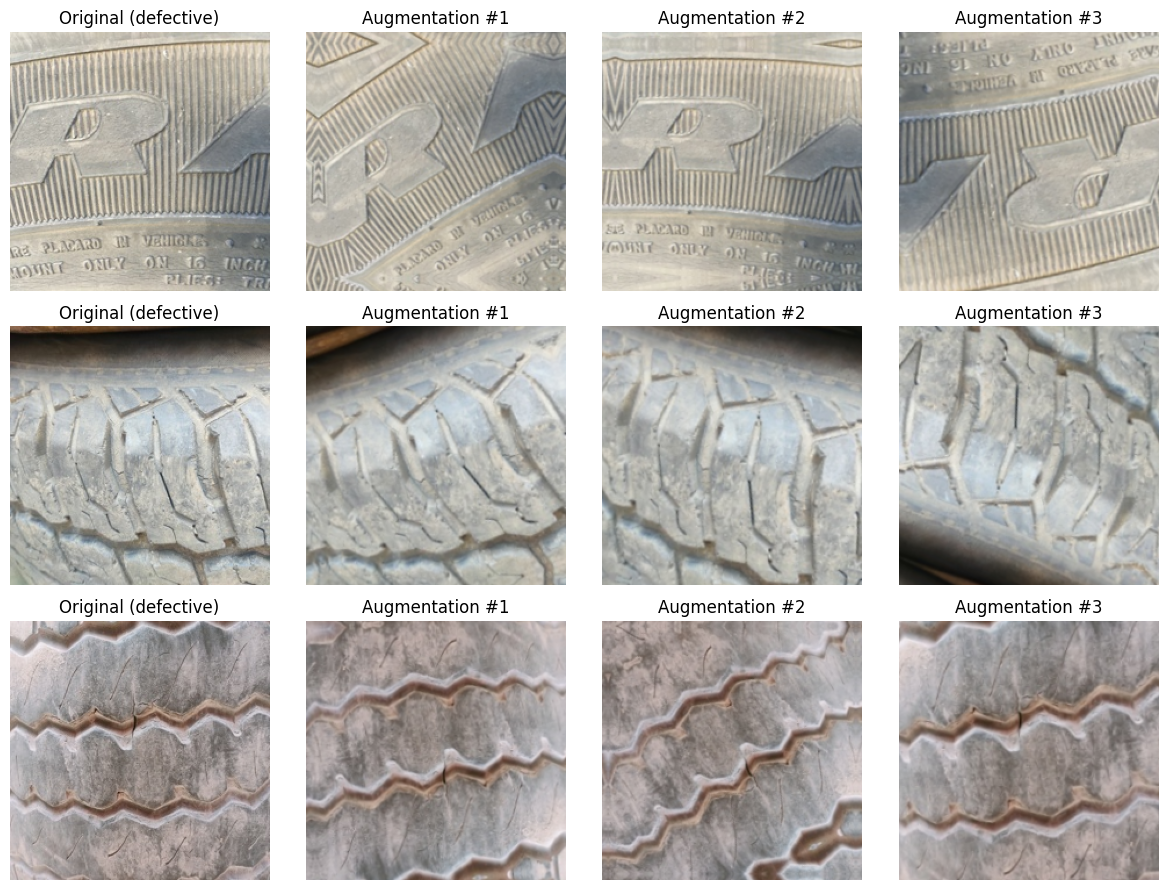

In [17]:
# Obtener las clases en el orden exacto de Keras (alfabético)
class_names = sorted([d.name for d in (DATA_DIR / "train").iterdir() if d.is_dir()])

# 1. Tomar 3 imágenes de muestra del primer lote
for imagenes, etiquetas in train_ds.take(1):
    muestras = imagenes[:3]
    labels_muestras = etiquetas[:3].numpy().astype(int).flatten()
    break

# 2. Graficar Original vs. 3 variaciones aleatorias
fig, axes = plt.subplots(3, 4, figsize=(12, 9))

for fila in range(3):
    img_original = muestras[fila]
    nombre_clase = class_names[labels_muestras[fila]]
    
    # Columna 0: Original
    axes[fila, 0].imshow(tf.cast(img_original, tf.uint8))
    axes[fila, 0].set_title(f"Original ({nombre_clase})")
    axes[fila, 0].axis("off")
    
    # Columnas 1 a 3: Variaciones con data_augmentation
    for col in range(1, 4):
        img_aumentada = data_augmentation(tf.expand_dims(img_original, 0), training=True)[0]
        img_visual = tf.clip_by_value(img_aumentada, 0, 255)
        
        axes[fila, col].imshow(tf.cast(img_visual, tf.uint8))
        axes[fila, col].set_title(f"Augmentation #{col}")
        axes[fila, col].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# Definición de la red
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(224, 224, 3)),
    
    # Data Augmentation y Normalización
    data_augmentation,
    tf.keras.layers.Rescaling(1.0 / 255.0),
    
    # Bloque Convolucional 1 (224x224 -> 112x112)
    tf.keras.layers.Conv2D(32, kernel_size=3, padding="same", use_bias=False),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Activation("relu"),
    tf.keras.layers.Conv2D(32, kernel_size=3, padding="same", use_bias=False),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Activation("relu"),
    tf.keras.layers.MaxPooling2D(pool_size=2),
    
    # Bloque Convolucional 2 (112x112 -> 56x56)
    tf.keras.layers.Conv2D(64, kernel_size=3, padding="same", use_bias=False),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Activation("relu"),
    tf.keras.layers.Conv2D(64, kernel_size=3, padding="same", use_bias=False),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Activation("relu"),
    tf.keras.layers.MaxPooling2D(pool_size=2),
    
    # Bloque Convolucional 3 (56x56 -> 28x28)
    tf.keras.layers.Conv2D(128, kernel_size=3, padding="same", use_bias=False),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Activation("relu"),
    tf.keras.layers.Conv2D(128, kernel_size=3, padding="same", use_bias=False),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Activation("relu"),
    tf.keras.layers.MaxPooling2D(pool_size=2),
    
    # Bloque Convolucional 4 (28x28 -> 14x14)
    tf.keras.layers.Conv2D(256, kernel_size=3, padding="same", use_bias=False),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Activation("relu"),
    tf.keras.layers.Conv2D(256, kernel_size=3, padding="same", use_bias=False),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Activation("relu"),
    tf.keras.layers.MaxPooling2D(pool_size=2),
    
    # Parte de clasificación
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dropout(0.4),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(1, activation="sigmoid")
], name="TyreCNN_DesdeCero")

In [ ]:
model.summary()

Model: "TyreCNN_DesdeCero"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augemtation (Sequential)   │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 224, 224, 32)   │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 112, 112, 64)   │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 112, 112, 64)   │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 56, 56, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 56, 56, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_5 (Activation)       │ (None, 56, 56, 128)    │             

 Total params: 1,191,649 (4.55 MB)

 Trainable params: 1,189,729 (4.54 MB)

 Non-trainable params: 1,920 (7.50 KB)

In [ ]:
# Compilación del modelo
model.compile(
    optimizer=tf.keras.optimizers.AdamW(
        learning_rate=CONFIG["learning_rate"],
        weight_decay=1e-4
    ),
    loss = "binary_crossentropy",
    metrics = [
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

In [21]:
# Callbacks
lista_callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(MODELS_DIR / "tyre_cnn_best.keras"),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=CONFIG["patience"],
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        verbose=1
    )
]

In [22]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=CONFIG["epochs"],
    callbacks=lista_callbacks
)

Epoch 1/30


2026-11-20 19:33:37.947626: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.
2026-11-20 19:33:37.959103: E tensorflow/core/grappler/optimizers/meta_optimizer.cc:961] PluggableGraphOptimizer failed: INVALID_ARGUMENT: Failed to deserialize the `graph_buf`.


41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.5937 - loss: 0.7923 - precision: 0.5400 - recall: 0.4462   
Epoch 1: val_loss improved from None to 0.71287, saving model to saved_models/tyre_cnn_best.keras
41/41 ━━━━━━━━━━━━━━━━━━━━ 51s 1s/step - accuracy: 0.6035 - loss: 0.7210 - precision: 0.5717 - recall: 0.4466 - val_accuracy: 0.5468 - val_loss: 0.7129 - val_precision: 0.2500 - val_recall: 0.0081 - learning_rate: 0.0010
Epoch 2/30
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 902ms/step - accuracy: 0.6574 - loss: 0.6278 - precision: 0.6379 - recall: 0.5043
Epoch 2: val_loss did not improve from 0.71287
41/41 ━━━━━━━━━━━━━━━━━━━━ 39s 940ms/step - accuracy: 0.6667 - loss: 0.6188 - precision: 0.6797 - recall: 0.4793 - val_accuracy: 0.4245 - val_loss: 0.8066 - val_precision: 0.4318 - val_recall: 0.9194 - learning_rate: 0.0010
Epoch 3/30
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 967ms/step - accuracy: 0.6604 - loss: 0.6215 - precision: 0.6268 - recall: 0.5503
Epoch 3: val_loss improved from 0.71287 to 0.69590, 

## Evolución de Pérdida y Exactitud

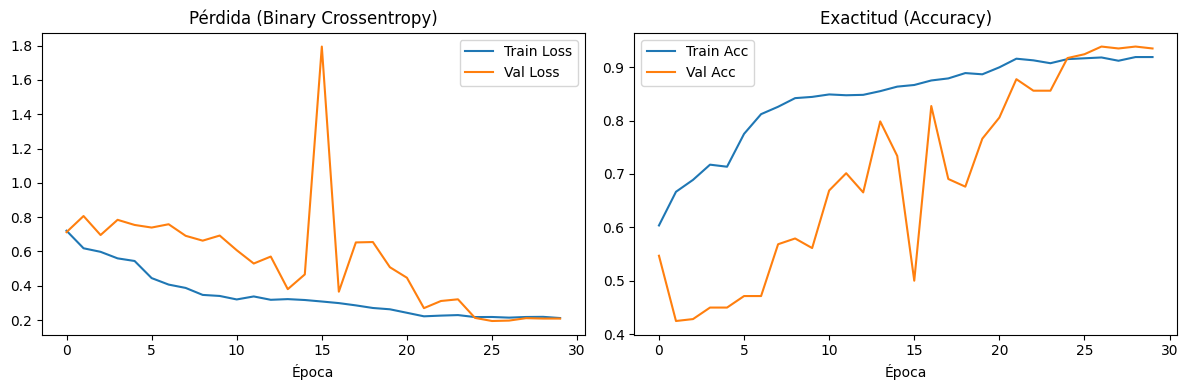

In [23]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(history.history["loss"], label="Train Loss")
ax1.plot(history.history["val_loss"], label="Val Loss")
ax1.set_title("Pérdida (Binary Crossentropy)")
ax1.set_xlabel("Época")
ax1.legend()

ax2.plot(history.history["accuracy"], label="Train Acc")
ax2.plot(history.history["val_accuracy"], label="Val Acc")
ax2.set_title("Exactitud (Accuracy)")
ax2.set_xlabel("Época")
ax2.legend()

plt.tight_layout()
plt.show()